# Cosmetics Product Analysis
## Project Scenario
 Perform data analysis of Cosmetics.CSV, the store wants to understand its product collection better.Provided CSV file to explore the data & share useful findings about product categories, brands, prices, ranking, & skin types.

## Project Objectives
* Understand and clean the dataset whereever it is needed.
* Summarize products, prices, and ratings.
* Create charts to show important patterns.
* Write simple conclusions based on the results.

## Dataset Overview
The file contains 1,472 product records and 11 columns.
These columns include:
- Label (category)
- Brand
- Name
- Price
- Rank
- Ingredients
- Skin-type flags: Combination, Dry, Normal, Oily, and Sensitive. 






# Project Tasks
##  1.Import Required Libraries¶
We will use:

 *Pandas for data manipulation and analysis
*Matplotlib for data visualization




In [3]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


# 2. Load the Dataset
The cosmetic product data is stored in a CSV file named cosmetics.csv

We use the read_csv() function from Pandas to load the data into a DataFrame.



In [4]:
df = pd.read_csv("cosmetics.csv")


# 3. Inspect the Dataset
Before performing analysis, we should understand what the dataset contains.

We will:

*Display the first five rows using head()
*Check column names and data types using info()



In [5]:
df.head()


,Label,Brand,Name,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive
0,Moisturizer,LA MER,Crème de la Mer,175,4.1,"Algae (Seaweed) Extract, Mineral Oil, Petrolat...",1,1,1,1,1
1,Moisturizer,SK-II,Facial Treatment Essence,179,4.1,"Galactomyces Ferment Filtrate (Pitera), Butyle...",1,1,1,1,1
2,Moisturizer,DRUNK ELEPHANT,Protini™ Polypeptide Cream,68,4.4,"Water, Dicaprylyl Carbonate, Glycerin, Ceteary...",1,1,1,1,0
3,Moisturizer,LA MER,The Moisturizing Soft Cream,175,3.8,"Algae (Seaweed) Extract, Cyclopentasiloxane, P...",1,1,1,1,1
4,Moisturizer,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,38,4.1,"Water, Snail Secretion Filtrate, Phenyl Trimet...",1,1,1,1,1


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1472 entries, 0 to 1471
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Label        1472 non-null   str    
 1   Brand        1472 non-null   str    
 2   Name         1472 non-null   str    
 3   Price        1472 non-null   int64  
 4   Rank         1472 non-null   float64
 5   Ingredients  1472 non-null   str    
 6   Combination  1472 non-null   int64  
 7   Dry          1472 non-null   int64  
 8   Normal       1472 non-null   int64  
 9   Oily         1472 non-null   int64  
 10  Sensitive    1472 non-null   int64  
dtypes: float64(1), int64(6), str(4)
memory usage: 126.6 KB


# 4. Data Cleaning
Data often contains duplicate records or incorrect data types.

In this dataset:

1. We will remove duplicate rows.
2. We will convert the `Price` column into numeric values.
3. Invalid Price values will be converted into missing values (`NaN`).
4. Missing Price values will be replaced with the median Price.
    

In [7]:

df.drop_duplicates(inplace=True)


## Convert Price into Numeric Data
The Price column may contain values that are not numeric.

Using pd.to_numeric() with errors="coerce" converts invalid values into NaN.

In [8]:
df["Price"] = pd.to_numeric(
    df["Price"],
    
    errors="coerce"
)

# Handle Missing Price Values
Missing Price values are replaced using the median Price.

The median is often preferred because it is less affected by extremely high or low Price values.

In [9]:
df["Price"] = df["Price"].fillna(
    df["Price"].median()
    
)

# 5. Descriptive Statistics
The describe() function provides statistical information about the numerical columns in the dataset.

It includes:

- Count
- Mean
- Standard deviation
- Minimum
- 25th percentile
- Median
- 75th percentile
- Maximum

In [10]:
df.describe()

,Price,Rank,Combination,Dry,Normal,Oily,Sensitive
count,1472.000000,1472.000000,1472.00000,1472.000000,1472.000000,1472.000000,1472.000000
mean,55.584239,4.153261,0.65625,0.614130,0.652174,0.607337,0.513587
std,45.014429,0.633918,0.47512,0.486965,0.476442,0.488509,0.499985
min,3.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,4.000000,0.00000,0.000000,0.000000,0.000000,0.000000
50%,42.500000,4.300000,1.00000,1.000000,1.000000,1.000000,1.000000
75%,68.000000,4.500000,1.00000,1.000000,1.000000,1.000000,1.000000
max,370.000000,5.000000,1.00000,1.000000,1.000000,1.000000,1.000000


In [11]:
print(df.isnull())

      Label  Brand   Name  Price   Rank  Ingredients  Combination    Dry  \
0     False  False  False  False  False        False        False  False   
1     False  False  False  False  False        False        False  False   
2     False  False  False  False  False        False        False  False   
3     False  False  False  False  False        False        False  False   
4     False  False  False  False  False        False        False  False   
...     ...    ...    ...    ...    ...          ...          ...    ...   
1467  False  False  False  False  False        False        False  False   
1468  False  False  False  False  False        False        False  False   
1469  False  False  False  False  False        False        False  False   
1470  False  False  False  False  False        False        False  False   
1471  False  False  False  False  False        False        False  False   

      Normal   Oily  Sensitive  
0      False  False      False  
1      False  False  

# 6. Rank-wise Price Analysis
We will calculate the average, minimum, and maximum product price.
The groupby() function groups Label according to their Rank, and mean() calculate the average, max, min,count Price.

In [12]:
Label_Price = (
    df.groupby("Label")["Price"]  
    .mean()
)

print(Label_Price)

Label
Cleanser       32.601423
Eye cream      63.602871
Face Mask      42.624060
Moisturizer    69.087248
Sun protect    45.905882
Treatment      79.177419
Name: Price, dtype: float64


In [13]:
Label_Count = (
    df.groupby("Label")
    .count()
)
print(Label_Count)

             Brand  Name  Price  Rank  Ingredients  Combination  Dry  Normal  \
Label                                                                          
Cleanser       281   281    281   281          281          281  281     281   
Eye cream      209   209    209   209          209          209  209     209   
Face Mask      266   266    266   266          266          266  266     266   
Moisturizer    298   298    298   298          298          298  298     298   
Sun protect    170   170    170   170          170          170  170     170   
Treatment      248   248    248   248          248          248  248     248   

             Oily  Sensitive  
Label                         
Cleanser      281        281  
Eye cream     209        209  
Face Mask     266        266  
Moisturizer   298        298  
Sun protect   170        170  
Treatment     248        248  


In [14]:
Max_Price = (
    df.groupby("Label")["Price"]
    .max()
)

print(Max_Price)

Label
Cleanser        95
Eye cream      260
Face Mask      250
Moisturizer    325
Sun protect    260
Treatment      370
Name: Price, dtype: int64


In [15]:
Min_Price = (
    df.groupby("Label")["Price"]
    .min()
)

print(Min_Price)

Label
Cleanser        4
Eye cream       5
Face Mask       3
Moisturizer     4
Sun protect    18
Treatment      18
Name: Price, dtype: int64


## Top 5 Brands in most Label in dataset

In [16]:

Top_5_Brand = (
    df["Brand"].value_counts().head(5))
print(Top_5_Brand)

Brand
CLINIQUE              79
SEPHORA COLLECTION    66
SHISEIDO              63
ORIGINS               54
MURAD                 47
Name: count, dtype: int64


## * Highest average rating


In [17]:
# Average rating by Labels sorted from highest to lowest
highest_rated_Labels = df.groupby("Label")["Rank"].mean().sort_values(ascending = False)
print(highest_rated_Labels)

Label
Cleanser       4.312456
Moisturizer    4.238591
Treatment      4.218145
Face Mask      4.166917
Sun protect    4.051176
Eye cream      3.806220
Name: Rank, dtype: float64


# 7. Correlation Analysis

## Correlation between Price & Ranks
Correlation measures the relationship between numerical variables.

The correlation coefficient generally ranges from:

- +1 → Strong positive relationship
- 0 → No linear relationship
- -1 → Strong negative relationship
We use numeric_only=True so that Pandas considers only numerical columns.

In [18]:
df.corr(numeric_only=True)

,Price,Rank,Combination,Dry,Normal,Oily,Sensitive
Price,1.000000,-0.025215,0.012575,0.065525,0.049230,0.003978,0.007621
Rank,-0.025215,1.000000,0.036904,0.026982,0.051926,0.021041,0.015946
Combination,0.012575,0.036904,1.000000,0.830784,0.927966,0.882528,0.689316
Dry,0.065525,0.026982,0.830784,1.000000,0.874436,0.745767,0.722367
Normal,0.049230,0.051926,0.927966,0.874436,1.000000,0.835227,0.713320
Oily,0.003978,0.021041,0.882528,0.745767,0.835227,1.000000,0.648097
Sensitive,0.007621,0.015946,0.689316,0.722367,0.713320,0.648097,1.000000


## Product Count for each Skin Type

In [19]:
# Product suitable for each skin type
Skin_Columns = ["Oily", "Dry", "Combination", "Sensitive", "Normal"]
Skin_Counts = df[Skin_Columns].sum()
print(Skin_Counts)

Oily           894
Dry            904
Combination    966
Sensitive      756
Normal         960
dtype: int64


# 8. Data Visualization
Visualization makes it easier to compare Price values across different Ranks.

We will create a bar chart showing the average Price for each Ranks.

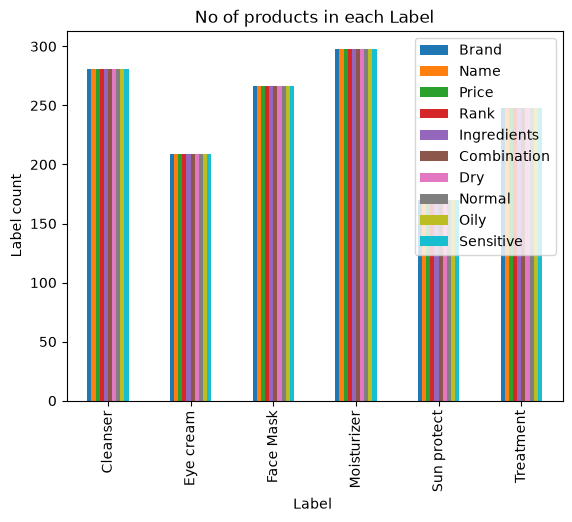

In [20]:
Label_Count.plot(
    kind="bar"
)

plt.title("No of products in each Label")
plt.xlabel("Label ")
plt.ylabel("Label count")

plt.show()

This graph shows the count of products across different skin types & product attributes for several categories.

### Top 5 Brands by Label Count

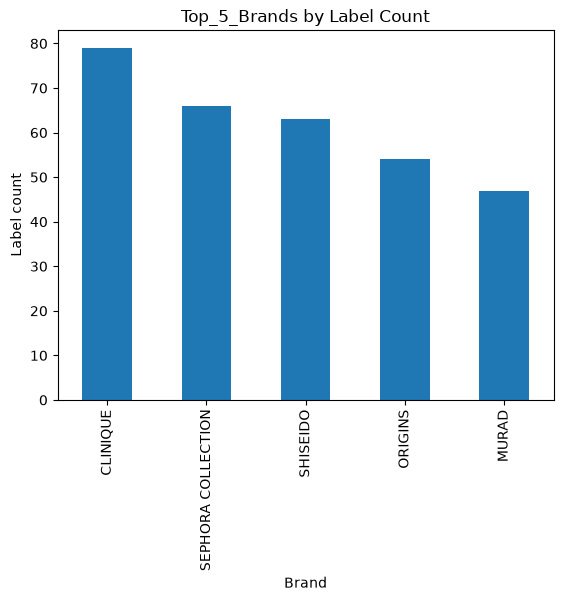

In [28]:
Top_5_Brand = (
    df["Brand"].value_counts().head(5))
Top_5_Brand.plot(kind = "bar")
plt.title("Top_5_Brands by Label Count")
plt.xlabel("Brand")
plt.ylabel("Label count")

plt.show()
    

This Visualization identifies the top 5 most prominent brands within the dataset. It reveals which manufactures have the highest product variety & market presence.

### Histogram  distribution of Label prices.

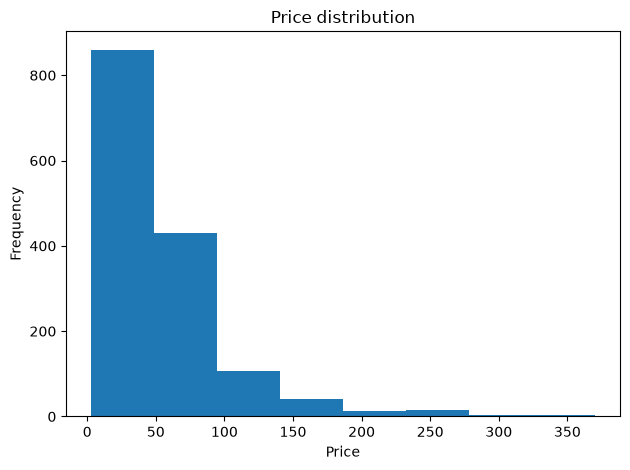

In [21]:
plt.hist(
    df["Price"],
    bins = 8
)
plt.title("Price distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

This histogram illustrates how product prices are ditributed . The peak shows the most common price range, while the long tail indicates the presence of premium, high-priced items

### Scatter plot Price compared with Rank

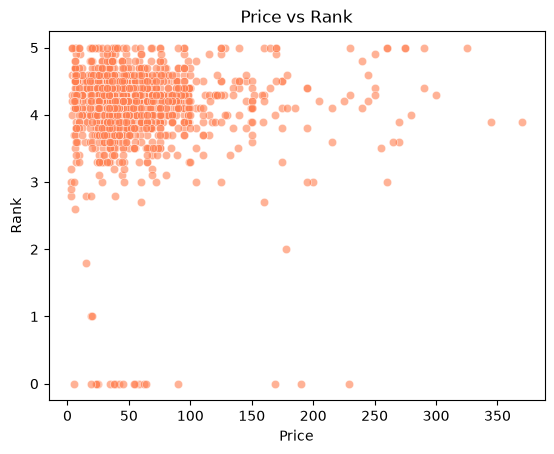

In [22]:
sns.scatterplot(data = df, x= "Price", y = "Rank", alpha = 0.6, color = "Coral")

plt.title("Price vs Rank")
plt.xlabel("Price")
plt.ylabel("Rank")
plt.show()

This plot examines relationship between product's price & its rank. It helps determine if higher priced products tend to achieve better ranking position.

### Optional chart: Skin-type flags

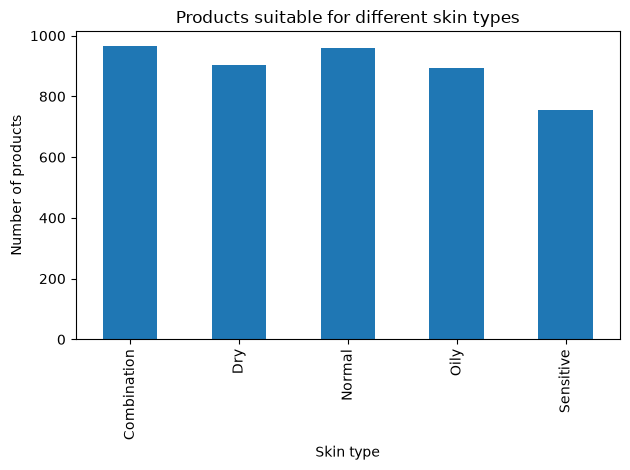

In [23]:
skin_cols = [
    c for c in 
    ["Combination", "Dry", "Normal", "Oily", "Sensitive",]
    if c in df. columns
]
if skin_cols:
    skin_counts = df[skin_cols].fillna(0).astype(bool).sum()

    skin_counts.plot(kind = "bar")
    plt.title("Products suitable for different skin types")
    plt.xlabel("Skin type")
    plt.ylabel("Number of products")
    plt.tight_layout()
    plt.show()
else:
     print("Skin-type columns not found.")   
    

# 9. Conclusion  

## * Three important findings

### 1) Category Dominance:
A significant majority of the product belong to a single dominant category.
e.g. Skincare or Makeup, indicating an inventory heavily skewed toward specific consumer needs.

### 2) Price Skewness:
The price distribution is heavily right-skewed, meaning the vast majority of items are budget-friendly, with only a few premium products driving up the maximum range.

### 3) Brand Concentration:
The top 5 brands contribute to a large percentage of the total product count, showing that a few major players command most of the catalog space.

## * Two Practical Recommendations

### 1. Inventory Diversification:
Expand product sourcing in underrepresented categories to capture niche markets & reduce reliance on a single dominant category.

### 2. Tiered Pricing Strategy:
Introduce midtier priced products to bridge the gap between low-cost budget items & highly expensive premium items, capturing mid-range consumer segments.

## * Limitation of the dataset
###  Lack of Performance Metrics:
The dataset lacks transaction history, customer revenue, and profit margin metrics. Consequently, we cannot determine which high-count products or top-ranked brands actually generate the most profit
